# Tsinghua University - Deep Learning Course <br> Assignment 1(b) Softmax Regression

## 1. Load Dataset


In [26]:
import os
import pathlib
import tqdm
# from tqdm.notebook import tqdm   # 适用于 Jupyter
import numpy as np
import pickle
import zipfile
import matplotlib.pyplot as plt
import matplotlib.cm as cm
%matplotlib inline


In [27]:
# Read from dataset file

with zipfile.ZipFile('data/cifar-10-python.zip', 'r') as z:
    def pickle_load_from_zip_entry(name):
        with z.open(name) as f:
            return pickle.load(f, encoding='latin1')

    label_names = pickle_load_from_zip_entry('cifar-10-batches-py/batches.meta')['label_names']
    print('label_names:', label_names)

    print('\nLoading train set ...')
    train_data_dicts = [
        pickle_load_from_zip_entry(f'cifar-10-batches-py/{filename}')
        for filename in ('data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5',)]
    train_data = np.concatenate([d['data'].astype(np.float32) for d in train_data_dicts]) / 255.
    train_labels = np.concatenate([d['labels'] for d in train_data_dicts])
    print(f'train_data: <np.array of shape: {train_data.shape} dtype: {train_data.dtype}>')
    print(f'train_labels: <np.array of shape: {train_labels.shape} dtype: {train_labels.dtype}>')

    print('\nLoading test set ...')
    test_data_dict = pickle_load_from_zip_entry('cifar-10-batches-py/test_batch')
    test_data = test_data_dict['data'].astype(np.float32) / 255.
    test_labels = np.array(test_data_dict['labels'])
    print(f'test_data: <np.array of shape: {test_data.shape} dtype: {test_data.dtype}>')
    print(f'test_labels: <np.array of shape: {test_labels.shape} dtype: {test_labels.dtype}>')


label_names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Loading train set ...


/var/folders/bl/kmvwq1ts1t96gqqcg2x9rhyr0000gn/T/ipykernel_2048/3508816361.py:6: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(f, encoding='latin1')


train_data: <np.array of shape: (50000, 3072) dtype: float32>
train_labels: <np.array of shape: (50000,) dtype: int64>

Loading test set ...
test_data: <np.array of shape: (10000, 3072) dtype: float32>
test_labels: <np.array of shape: (10000,) dtype: int64>


In [28]:
# Preview dataset

_ = plt.figure(figsize=(10, 10))
_ = plt.title('CIFAR-10 Preview')
for label_index, label_name in enumerate(label_names):
    for img_index, img_data in enumerate(test_data[test_labels == label_index][:10]):
        _ = plt.imshow(
            np.moveaxis(np.reshape(img_data, (3, 32, 32)), 0, 2),
            interpolation='nearest', extent=(img_index, img_index + 1, label_index, label_index + 1))
_ = plt.xticks([])
_ = plt.yticks(np.arange(len(label_names)) + 0.5, label_names)
_ = plt.xlim(0, 10)
_ = plt.ylim(0, len(label_names))

<Figure size 1000x1000 with 1 Axes>

## 2. Training

In [29]:
# Note on Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.
batch_size = 100
max_epoch = 10
lr = 0.001      # learning rate
momentum = 0.9  # momentum
lambd = 0.001   # 正则化系数
eps = 1e-12     # 防止 log(0)
np.random.seed(42)   # 固定种子

# Note on Initialize, Parameters. Refer to the archived source for the detailed original comment.
D = train_data.shape[1] 
K = len(label_names)                # 类别数 
W = np.random.randn(D, K) * 0.001   # weight
b = np.zeros(K)                     # bias


# 动量变量
v_W = np.zeros_like(W)
v_b = np.zeros_like(b)

# 辅助函数
def softmax(u):
    u_shift = u - np.max(u, axis=1, keepdims=True)  # 数值稳定：减去每行的最大值
    exp_u = np.exp(u_shift)
    return exp_u / np.sum(exp_u, axis=1, keepdims=True)

def cross_entropy_loss(probs, y_onehot, eps):
    """
    probs: (batch_size, K) softmax函数输出的概率
    y_onehot: (batch_size, K) one-hot 真实标签
    """
    probs_clipped = np.clip(probs, eps, 1 - eps)  # 为避免 log(0)，对概率进行裁剪
    # 每个mini-batch里的损失求和
    loss_per_sample = -np.sum(y_onehot * np.log(probs_clipped), axis=1)
    return np.mean(loss_per_sample)   # 对所有样本取平均

# 记录
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(max_epoch):
    # Note on Training, Data. Refer to the archived source for the detailed original comment.
    perm = np.random.permutation(len(train_data))
    X_shuffled = train_data[perm]        
    y_shuffled = train_labels[perm]
        
    steps_per_epoch = np.ceil(len(train_data) / batch_size).astype(int)
    progress_bar = tqdm.tqdm(range(steps_per_epoch), mininterval=9999)

    epoch_losses = []
    epoch_accuracies = []
    for step_index in progress_bar:
        # fetch next batch of training data
        X = X_shuffled[step_index * batch_size:(step_index + 1) * batch_size]           # train_data as x (shape: [batch_size, 3072])
        y_true = y_shuffled[step_index * batch_size:(step_index + 1) * batch_size]    # train_labels as y (shape: [batch_size,])
        y_true = np.eye(K)[y_true]     #将整数标签（0~9）转换为 one-hot 向量（长度为 10 的二进制向量）                                                # make one-hot (shape: [batch_size, 10])
        current_batch_size = len(X)
        
        # TODO: forward with softmax
        z = X @ W + b
        probs = softmax(z)     # h_k(x) in the slides

        # TODO: calculate cross-entropy loss & accuracy
        loss = cross_entropy_loss(probs, y_true, eps)
        
        pred_labels = np.argmax(probs, axis=1)         # (batch_size, )
        true_labels = np.argmax(y_true, axis=1)
        accuracy = np.mean(pred_labels == true_labels)

        epoch_losses.append(loss)
        epoch_accuracies.append(accuracy)
        progress_bar.set_description(f'loss {loss:.3f} acc {accuracy:.3f}')

        # TODO: update weights, don't forget momentum
        error = probs - y_true
        grad_W = (X.T @ error)/current_batch_size + lambd * W
        grad_b = np.mean(error, axis=0) 

        # momentum
        v_W = momentum * v_W + lr * grad_W
        W -= v_W
        v_b = momentum * v_b + lr * grad_b
        b -= v_b

    # 记录
    train_losses.append(np.mean(epoch_losses))
    train_accuracies.append(np.mean(epoch_accuracies))

    # test accuracies
    X_test = test_data
    y_true_test = test_labels
    y_true_test = np.eye(K)[y_true_test]     # make one-hot

    # TODO: test set: forward with softmax
    z_test = X_test @ W + b
    probs_test = softmax(z_test)      # h_k(x) in the slides

    # TODO: test set: calculate cross-entropy loss & accuracy
    test_loss = cross_entropy_loss(probs_test, y_true_test, eps)

    test_pred_labels = np.argmax(probs_test, axis=1)
    test_true_labels = np.argmax(y_true_test, axis=1)
    test_accuracy = np.mean(test_pred_labels == test_true_labels)

    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)
    print(f'  - test acc: {test_accuracy:.3f}')

loss 2.095 acc 0.250: 100%|█████████████████| 500/500 [00:00<00:00, 1110.19it/s]


  - test acc: 0.334


loss 1.865 acc 0.290: 100%|█████████████████| 500/500 [00:00<00:00, 1047.20it/s]


  - test acc: 0.366


loss 1.867 acc 0.370: 100%|█████████████████| 500/500 [00:00<00:00, 1123.52it/s]


  - test acc: 0.378


... (10 outputs left out)

loss 1.809 acc 0.430: 100%|█████████████████| 500/500 [00:00<00:00, 1102.20it/s]


  - test acc: 0.390


loss 1.616 acc 0.440: 100%|█████████████████| 500/500 [00:00<00:00, 1031.97it/s]


  - test acc: 0.390


In [30]:
train_accuracies

[np.float64(0.308),
 np.float64(0.36222),
 np.float64(0.37296),
 np.float64(0.38014),
 np.float64(0.3851800000000001),
 np.float64(0.3887),
 np.float64(0.39634),
 np.float64(0.39696),
 np.float64(0.40146000000000004),
 np.float64(0.40184000000000003)]

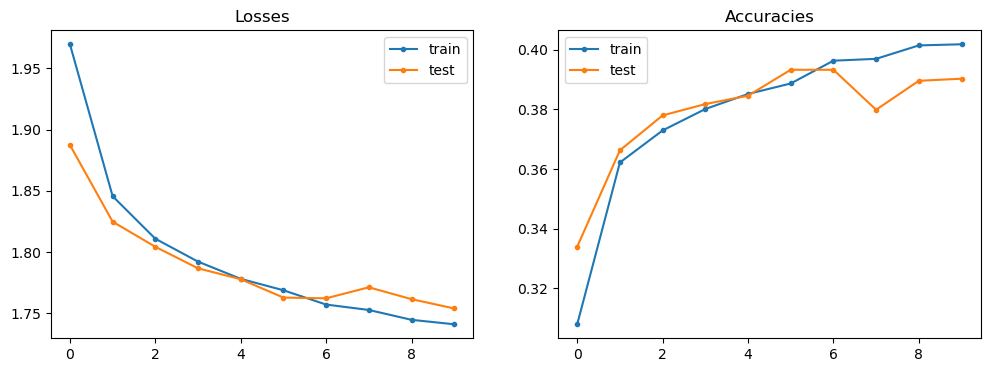

In [21]:
 # plot loss & accuracy curve
fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 4))
a0.set_title('Losses')
a0.plot(train_losses, marker='.', label='train')
a0.plot(test_losses, marker='.', label='test')
a0.legend()
a1.set_title('Accuracies')
a1.plot(train_accuracies, marker='.', label='train')
a1.plot(test_accuracies, marker='.', label='test')
a1.legend()
plt.show()

### Results and Analysis / Results / Analysis

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

Loss:
Accuracies：


### Experiment Notes

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [33]:
# General Function
def train_softmax(train_data, train_labels, label_names, test_data, test_labels, 
                  use_bias=True, use_momentum=True, max_epoch=10, batch_size=100, 
                  lr=0.001, momentum=0.9, lambd=0.001, eps=1e-12):

    # 辅助函数
    def softmax(u):
        u_shift = u - np.max(u, axis=1, keepdims=True)
        exp_u = np.exp(u_shift)
        return exp_u / np.sum(exp_u, axis=1, keepdims=True)

    def cross_entropy_loss(probs, y_onehot, eps):
        probs_clipped = np.clip(probs, eps, 1 - eps)
        loss_per_sample = -np.sum(y_onehot * np.log(probs_clipped), axis=1)
        return np.mean(loss_per_sample)   # 对所有样本取平均

    
    # Note on Initialize. Refer to the archived source for the detailed original comment.
    D = train_data.shape[1]
    K = len(label_names)
    W = np.random.randn(D, K) * 0.001
    b = np.zeros(K) # 有无偏置都用同样形状，但梯度可设零
    v_W = np.zeros_like(W)
    v_b = np.zeros_like(b)
    
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []
    n_samples = len(train_data)
    
    for epoch in range(max_epoch):
        # Note on Training, Data. Refer to the archived source for the detailed original comment.
        perm = np.random.permutation(n_samples)
        X_shuffled = train_data[perm]        
        y_shuffled = train_labels[perm]
        
        # Note on Compute. Refer to the archived source for the detailed original comment.
        steps_per_epoch = (n_samples + batch_size - 1) // batch_size
        
        epoch_losses = []
        epoch_accs = []
        
        for step_index in range(steps_per_epoch):
            # fetch next batch of training data
            start = step_index * batch_size
            end = min(start + batch_size, n_samples)   # 确保不越界
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]
            y_onehot = np.eye(K)[y_batch]
            current_batch_size = len(X_batch)
            
            # 前向
            logits = X_batch @ W + b
            probs = softmax(logits)
            loss = cross_entropy_loss(probs, y_onehot, eps)
            # Note on Accuracy. Refer to the archived source for the detailed original comment.
            pred_labels = np.argmax(probs, axis=1)         # (batch_size, )
            true_labels = np.argmax(y_onehot, axis=1)
            accuracy = np.mean(pred_labels == true_labels)

            epoch_losses.append(loss)
            epoch_accs.append(accuracy)
        
            # Note on Gradient. Refer to the archived source for the detailed original comment.
            error = probs - y_onehot
            grad_W = (X_batch.T @ error)/current_batch_size + lambd * W
            grad_b = np.mean(error, axis=0)
            if not use_bias:
                grad_b = np.zeros_like(grad_b)   # 禁用偏置更新
                
            # 更新
            if use_momentum:
                v_W = momentum * v_W + lr * grad_W
                W -= v_W
                v_b = momentum * v_b + lr * grad_b
                b -= v_b
            else:
                W -= lr * grad_W
                b -= lr * grad_b
                
        # Note on Accuracy. Refer to the archived source for the detailed original comment.
        train_losses.append(np.mean(epoch_losses))
        train_accs.append(np.mean(epoch_accs))

        # test accuracies
        y_test_onehot = np.eye(K)[test_labels]
        logits_test = test_data @ W + b
        probs_test = softmax(logits_test)
        test_loss = cross_entropy_loss(probs_test, y_test_onehot, eps)
        test_pred = np.argmax(probs_test, axis=1)
        test_accuracy = np.mean(test_pred == test_labels)

        test_losses.append(test_loss)
        test_accs.append(test_accuracy)
        print(f'Epoch {epoch+1}: train loss {train_losses[-1]:.4f}, train acc {train_accs[-1]:.4f} | test loss {test_loss:.4f}, test acc {test_accuracy:.4f}')
        
    return train_losses, test_losses, train_accs, test_accs

## 3. Bias or not

In [17]:
train_losses, test_losses, train_accuracies, test_accuracies = train_softmax(
    train_data, train_labels, label_names, test_data, test_labels,
    use_bias=True
)

Epoch 1: train loss 1.9704, train acc 0.3104 | test loss 1.8726, test acc 0.3461
Epoch 2: train loss 1.8441, train acc 0.3610 | test loss 1.8287, test acc 0.3613
Epoch 3: train loss 1.8116, train acc 0.3723 | test loss 1.8093, test acc 0.3700
Epoch 4: train loss 1.7913, train acc 0.3806 | test loss 1.7814, test acc 0.3840
Epoch 5: train loss 1.7785, train acc 0.3857 | test loss 1.7772, test acc 0.3859
Epoch 6: train loss 1.7689, train acc 0.3894 | test loss 1.7720, test acc 0.3891
Epoch 7: train loss 1.7603, train acc 0.3935 | test loss 1.7607, test acc 0.3931
Epoch 8: train loss 1.7504, train acc 0.3981 | test loss 1.7534, test acc 0.3939
Epoch 9: train loss 1.7437, train acc 0.4020 | test loss 1.7616, test acc 0.3864
Epoch 10: train loss 1.7392, train acc 0.4039 | test loss 1.7608, test acc 0.3884


In [14]:
train_losses_nobias, test_losses_nobias, train_accuracies_nobias, test_accuracies_nobias = train_softmax(
    train_data, train_labels, label_names, test_data, test_labels,
    use_bias=False
)

Epoch 1: train loss 1.9708, train acc 0.3056 | test loss 1.8826, test acc 0.3491
Epoch 2: train loss 1.8450, train acc 0.3613 | test loss 1.8202, test acc 0.3780
Epoch 3: train loss 1.8128, train acc 0.3724 | test loss 1.8095, test acc 0.3683
Epoch 4: train loss 1.7945, train acc 0.3802 | test loss 1.7891, test acc 0.3767
Epoch 5: train loss 1.7793, train acc 0.3872 | test loss 1.7899, test acc 0.3718
Epoch 6: train loss 1.7713, train acc 0.3889 | test loss 1.7742, test acc 0.3819
Epoch 7: train loss 1.7626, train acc 0.3935 | test loss 1.7648, test acc 0.3919
Epoch 8: train loss 1.7538, train acc 0.3968 | test loss 1.7584, test acc 0.3923
Epoch 9: train loss 1.7486, train acc 0.3987 | test loss 1.7689, test acc 0.3785
Epoch 10: train loss 1.7458, train acc 0.3976 | test loss 1.7665, test acc 0.3871


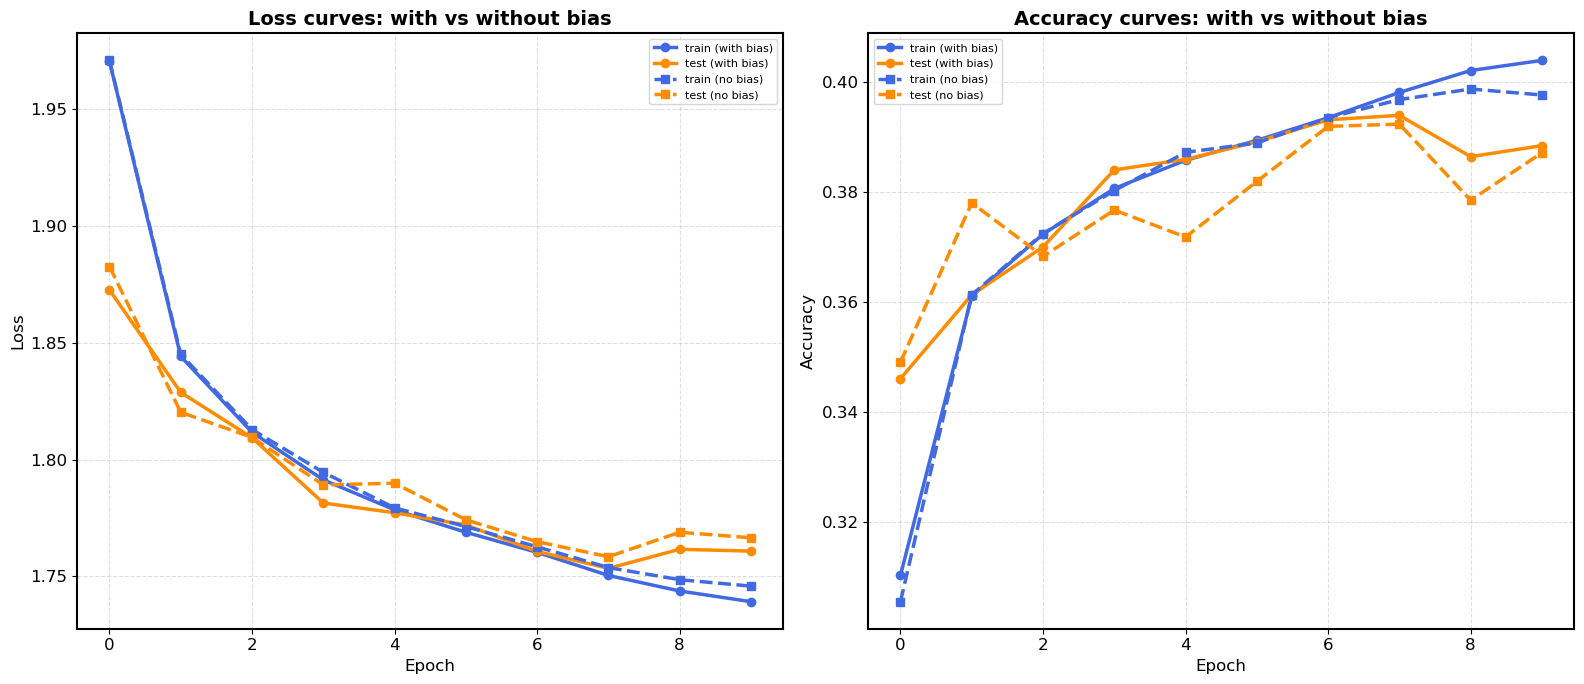

In [18]:
# Note on Parameters, Settings. Refer to the archived source for the detailed original comment.
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.5

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(16, 7))

# Note on Define. Refer to the archived source for the detailed original comment.
# Note on Training, Testing. Refer to the archived source for the detailed original comment.
# 有偏置用实线 (Solid: '-')，无偏置用虚线 (Dashed: '--')
color_train = 'RoyalBlue'
color_test = 'DarkOrange'
linewidth_solid = 2.5
linewidth_dashed = 2.5
marker_size = 6

# ===== Loss 对比图 =====
# 有偏置（实线）
ax_loss.plot(train_losses, marker='o', linestyle='-', label='train (with bias)', 
             color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_loss.plot(test_losses, marker='o', linestyle='-', label='test (with bias)', 
             color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无偏置（虚线，加粗）
ax_loss.plot(train_losses_nobias, marker='s', linestyle='--', label='train (no bias)', 
             color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_loss.plot(test_losses_nobias, marker='s', linestyle='--', label='test (no bias)', 
             color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_loss.set_title('Loss curves: with vs without bias', fontsize=14, fontweight='bold')
ax_loss.set_xlabel('Epoch')
ax_loss.set_ylabel('Loss')
ax_loss.legend(fontsize=8)
ax_loss.grid(True, linestyle='--', alpha=0.4) # 网格淡一点

# ===== Accuracy 对比图 =====
# 有偏置（实线）
ax_acc.plot(train_accuracies, marker='o', linestyle='-', label='train (with bias)', 
            color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_acc.plot(test_accuracies, marker='o', linestyle='-', label='test (with bias)', 
            color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无偏置（虚线）
ax_acc.plot(train_accuracies_nobias, marker='s', linestyle='--', label='train (no bias)', 
            color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_acc.plot(test_accuracies_nobias, marker='s', linestyle='--', label='test (no bias)', 
            color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_acc.set_title('Accuracy curves: with vs without bias', fontsize=14, fontweight='bold')
ax_acc.set_xlabel('Epoch')
ax_acc.set_ylabel('Accuracy')
ax_acc.legend(fontsize=8)
ax_acc.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Results and Analysis / Results / Analysis

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


## 4.Momentum or not

In [16]:
np.random.seed(42)   # 固定种子

train_losses_nomomentum, test_losses_nomomentum, train_accuracies_nomomentum, test_accuracies_nomomentum = train_softmax(
    train_data, train_labels, label_names, test_data, test_labels,
    use_momentum=False
)

Epoch 1: train loss 2.1730, train acc 0.2354 | test loss 2.0893, test acc 0.2931
Epoch 2: train loss 2.0455, train acc 0.3036 | test loss 2.0115, test acc 0.3244
Epoch 3: train loss 1.9874, train acc 0.3253 | test loss 1.9675, test acc 0.3345
Epoch 4: train loss 1.9509, train acc 0.3370 | test loss 1.9388, test acc 0.3398
Epoch 5: train loss 1.9256, train acc 0.3452 | test loss 1.9166, test acc 0.3455
Epoch 6: train loss 1.9063, train acc 0.3514 | test loss 1.9005, test acc 0.3542
Epoch 7: train loss 1.8912, train acc 0.3552 | test loss 1.8869, test acc 0.3568
Epoch 8: train loss 1.8789, train acc 0.3594 | test loss 1.8761, test acc 0.3581
Epoch 9: train loss 1.8685, train acc 0.3626 | test loss 1.8673, test acc 0.3634
Epoch 10: train loss 1.8598, train acc 0.3658 | test loss 1.8588, test acc 0.3616


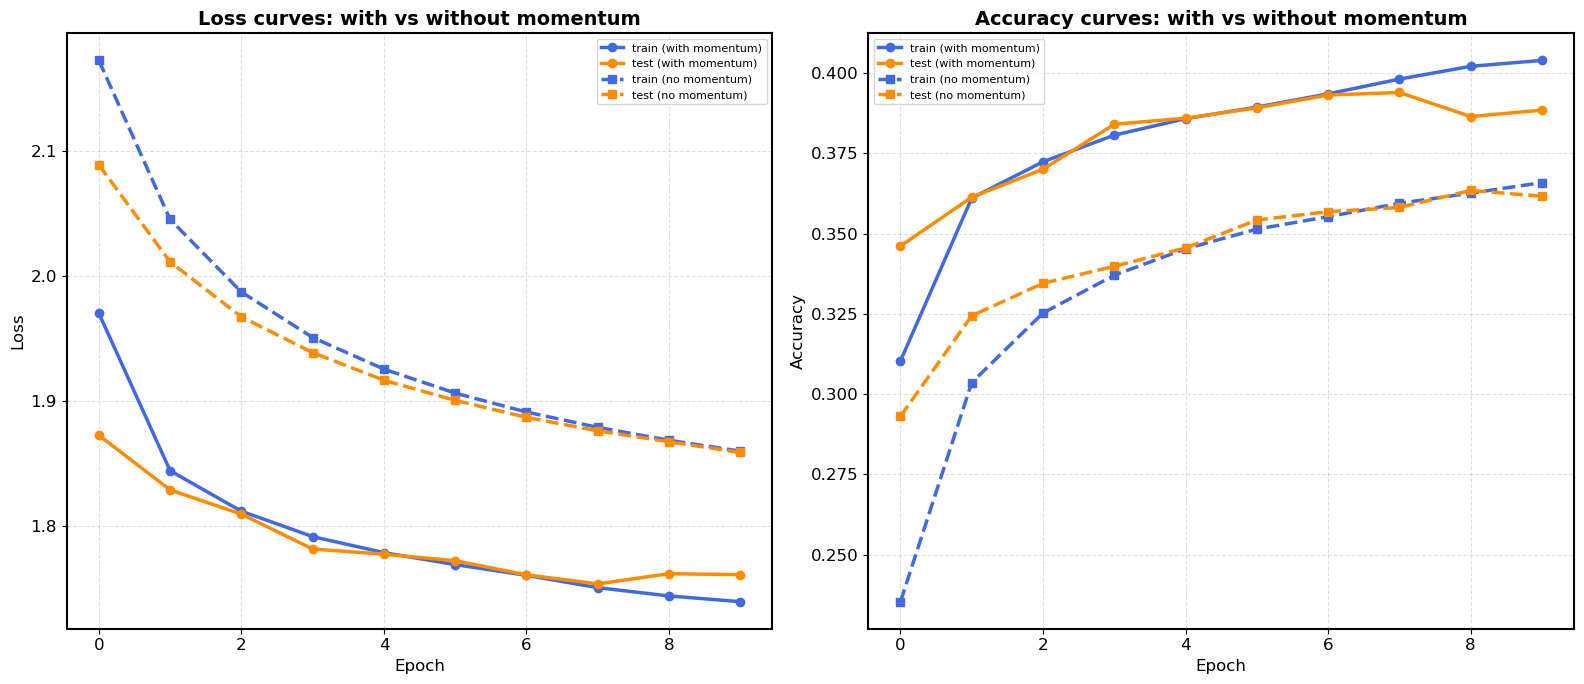

In [19]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(16, 7))

# ===== Loss 对比图 =====
# 有momentums（实线）
ax_loss.plot(train_losses, marker='o', linestyle='-', label='train (with momentum)', 
             color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_loss.plot(test_losses, marker='o', linestyle='-', label='test (with momentum)', 
             color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无momentums（虚线，加粗）
ax_loss.plot(train_losses_nomomentum, marker='s', linestyle='--', label='train (no momentum)', 
             color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_loss.plot(test_losses_nomomentum, marker='s', linestyle='--', label='test (no momentum)', 
             color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_loss.set_title('Loss curves: with vs without momentum', fontsize=14, fontweight='bold')
ax_loss.set_xlabel('Epoch')
ax_loss.set_ylabel('Loss')
ax_loss.legend(fontsize=8)
ax_loss.grid(True, linestyle='--', alpha=0.4) # 网格淡一点

# ===== Accuracy 对比图 =====
# 有偏置（实线）
ax_acc.plot(train_accuracies, marker='o', linestyle='-', label='train (with momentum)', 
            color=color_train, linewidth=linewidth_solid, markersize=marker_size)
ax_acc.plot(test_accuracies, marker='o', linestyle='-', label='test (with momentum)', 
            color=color_test, linewidth=linewidth_solid, markersize=marker_size)
# 无偏置（虚线）
ax_acc.plot(train_accuracies_nomomentum, marker='s', linestyle='--', label='train (no momentum)', 
            color=color_train, linewidth=linewidth_dashed, markersize=marker_size)
ax_acc.plot(test_accuracies_nomomentum, marker='s', linestyle='--', label='test (no momentum)', 
            color=color_test, linewidth=linewidth_dashed, markersize=marker_size)

ax_acc.set_title('Accuracy curves: with vs without momentum', fontsize=14, fontweight='bold')
ax_acc.set_xlabel('Epoch')
ax_acc.set_ylabel('Accuracy')
ax_acc.legend(fontsize=8)
ax_acc.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Results and Analysis / Results / Analysis

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

- Accuracy:
- Loss：


### Training / Weights / Data

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

5. Batch Size impact


In [23]:
batch_sizes = [5, 16, 32, 64, 100]

results = {}  # 存储每个 batch size 的训练结果

for bs in batch_sizes:
    print(f"\n===== Training with batch_size = {bs} =====")
    train_losses, test_losses, train_accs, test_accs = train_softmax(
        train_data, train_labels, label_names, test_data, test_labels,
        batch_size=bs,
        lr=0.001,             # batch size 变大时，梯度估计更准，通常需要减小学习率
        max_epoch=10          # 固定 epoch 数
    )
    results[bs] = {
        'train_losses': train_losses,
        'test_losses': test_losses,
        'train_accs': train_accs,
        'test_accs': test_accs
    }


===== Training with batch_size = 5 =====
Epoch 1: train loss 2.1665, train acc 0.2965 | test loss 2.1511, test acc 0.3174
Epoch 2: train loss 2.1020, train acc 0.3262 | test loss 2.0833, test acc 0.3598
Epoch 3: train loss 2.0676, train acc 0.3352 | test loss 2.2495, test acc 0.2973
Epoch 4: train loss 2.0392, train acc 0.3426 | test loss 1.9316, test acc 0.3546
Epoch 5: train loss 2.0474, train acc 0.3457 | test loss 2.4187, test acc 0.2830
Epoch 6: train loss 2.0281, train acc 0.3475 | test loss 1.8766, test acc 0.3613
Epoch 7: train loss 2.0306, train acc 0.3487 | test loss 2.1896, test acc 0.3025
Epoch 8: train loss 2.0112, train acc 0.3506 | test loss 1.9058, test acc 0.3485
Epoch 9: train loss 2.0087, train acc 0.3488 | test loss 2.2191, test acc 0.3222
Epoch 10: train loss 2.0192, train acc 0.3502 | test loss 2.0891, test acc 0.3089

===== Training with batch_size = 16 =====
Epoch 1: train loss 1.9227, train acc 0.3219 | test loss 1.9152, test acc 0.3327
Epoch 2: train loss 1.8

In [24]:
# 获取真正存在的 batch size
available_bs = sorted(results.keys())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Note on Plot, Data, Loop. Refer to the archived source for the detailed original comment.
for bs in available_bs:
    data = results[bs]
    
    # Note on Generate. Refer to the archived source for the detailed original comment.
    epochs = np.arange(1, len(data['train_losses']) + 1)
    
    # 1. 左上：Train Loss
    axes[0, 0].plot(epochs, data['train_losses'], marker='o', linestyle='-', label=f'bs={bs}')
    
    # 2. 右上：Test Loss
    axes[0, 1].plot(epochs, data['test_losses'], marker='o', linestyle='-', label=f'bs={bs}')
    
    # 3. 左下：Train Accuracy
    axes[1, 0].plot(epochs, data['train_accs'], marker='o', linestyle='-', label=f'bs={bs}')
    
    # 4. 右下：Test Accuracy
    axes[1, 1].plot(epochs, data['test_accs'], marker='o', linestyle='-', label=f'bs={bs}')

# Note on Settings. Refer to the archived source for the detailed original comment.
axes[0, 0].set_title('Train Loss', fontsize=14)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].set_xlabel('Epoch', fontsize=12) 
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].set_title('Test Loss', fontsize=14)
axes[0, 1].set_ylabel('Loss', fontsize=12)
axes[0, 1].set_xlabel('Epoch', fontsize=12) 
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].set_title('Train Accuracy', fontsize=14)
axes[1, 0].set_ylabel('Accuracy', fontsize=12)
axes[1, 0].set_xlabel('Epoch', fontsize=12) 
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].set_title('Test Accuracy', fontsize=14)
axes[1, 1].set_ylabel('Accuracy', fontsize=12)
axes[1, 1].set_xlabel('Epoch', fontsize=12) 
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Note on Settings. Refer to the archived source for the detailed original comment.
plt.suptitle('Softmax Batch Size Comparison - Fixed Epochs (10 epochs, lr=1e-3)', fontsize=16, y=0.98)

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()

<Figure size 1400x1000 with 4 Axes>

### Results and Analysis / Results / Analysis

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Model / Training / Dataset

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

6. Fix steps of each epoch


In [25]:
import gc
gc.collect()

40988

In [6]:
def train_softmax_fixed_steps(train_data, train_labels, label_names, test_data, test_labels,
                              use_bias=True, use_momentum=True, total_steps=5000, batch_size=100,
                              lr=0.001, momentum=0.9, lambd=0.001, eps=1e-12,
                              record_every=500):  # 每隔 record_every 步记录一次

    # 辅助函数
    def softmax(u):
        u_shift = u - np.max(u, axis=1, keepdims=True)
        exp_u = np.exp(u_shift)
        return exp_u / np.sum(exp_u, axis=1, keepdims=True)

    def cross_entropy_loss(probs, y_onehot, eps):
        probs_clipped = np.clip(probs, eps, 1 - eps)
        loss_per_sample = -np.sum(y_onehot * np.log(probs_clipped), axis=1)
        return np.mean(loss_per_sample)
    
    # Note on Initialize. Refer to the archived source for the detailed original comment.
    D = train_data.shape[1]
    K = len(label_names)
    W = np.random.randn(D, K) * 0.001
    b = np.zeros(K)
    v_W = np.zeros_like(W)
    v_b = np.zeros_like(b)
    n_samples = len(train_data)
    
    # Note on Settings, Data. Refer to the archived source for the detailed original comment.
    perm = np.random.permutation(n_samples)
    X_shuffled = train_data[perm]
    y_shuffled = train_labels[perm]
    ptr = 0   # 当前 epoch 中已取到的位置
    
    step_counter = 0 # 用 step_counter 代替 epoch 循环
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []
    step_records = []
    
    while step_counter < total_steps:
        # Note on Data. Refer to the archived source for the detailed original comment.
        if ptr == 0 and step_counter > 0:
            perm = np.random.permutation(n_samples)
            X_shuffled = train_data[perm]
            y_shuffled = train_labels[perm]
        
        # 取当前 batch（最后一个可能不完整）
        end = min(ptr + batch_size, n_samples)
        X_batch = X_shuffled[ptr:end]
        y_batch = y_shuffled[ptr:end]
        y_onehot = np.eye(K)[y_batch]
        current_batch_size = len(X_batch)
        
        # 前向
        logits = X_batch @ W + b
        probs = softmax(logits)
        loss = cross_entropy_loss(probs, y_onehot, eps)
        
        pred_labels = np.argmax(probs, axis=1)
        true_labels = np.argmax(y_onehot, axis=1)
        accuracy = np.mean(pred_labels == true_labels)
        
        # 按固定步数记录
        if (step_counter + 1) % record_every == 0 or step_counter == total_steps - 1:
            # Note on Testing, Evaluation. Refer to the archived source for the detailed original comment.
            y_test_onehot = np.eye(K)[test_labels]
            logits_test = test_data @ W + b
            probs_test = softmax(logits_test)
            test_loss = cross_entropy_loss(probs_test, y_test_onehot, eps)
            test_pred = np.argmax(probs_test, axis=1)
            test_acc = np.mean(test_pred == test_labels)

            step_records.append(step_counter + 1)
            train_losses.append(loss)
            train_accs.append(accuracy)
            test_losses.append(test_loss)
            test_accs.append(test_acc)

            print(f"Step {step_counter+1}: train loss {loss:.4f}, train acc {accuracy:.4f} | test loss {test_loss:.4f}, test acc {test_acc:.4f}")

        # Note on Gradient. Refer to the archived source for the detailed original comment.
        error = probs - y_onehot
        grad_W = (X_batch.T @ error) / current_batch_size + lambd * W
        grad_b = np.mean(error, axis=0)
        if not use_bias:
            grad_b = np.zeros_like(grad_b)

        # 更新
        if use_momentum:
            v_W = momentum * v_W + lr * grad_W
            W -= v_W
            v_b = momentum * v_b + lr * grad_b
            b -= v_b
        else:
            W -= lr * grad_W
            b -= lr * grad_b

         # 更新指针
        ptr = end
        if ptr == n_samples:
            ptr = 0   # 完成一个 epoch，下一个循环会打乱数据
        
        step_counter += 1

    return step_records, train_losses, test_losses, train_accs, test_accs

In [7]:
total_steps = 5000   # 固定参数更新次数
record_every = 100   # 每 100 步记录一次
batch_sizes_fixed_setps = [16, 64, 128, 256]

results_fixed_setps = {}
for bs in batch_sizes_fixed_setps:
    print(f"\n===== Fixed total steps = {total_steps}, batch_size = {bs} =====")
    steps, train_losses, test_losses, train_accs, test_accs = train_softmax_fixed_steps(
        train_data, train_labels, label_names, test_data, test_labels,
        total_steps=total_steps, batch_size=bs,
        lr=0.001,  
        record_every=record_every
    )
    results_fixed_setps[bs] = {
        'steps': steps,
        'train_losses': train_losses,
        'test_losses': test_losses,
        'train_accs': train_accs,
        'test_accs': test_accs
    }


===== Fixed total steps = 5000, batch_size = 16 =====
Step 100: train loss 2.1568, train acc 0.1875 | test loss 2.1380, test acc 0.2454
Step 200: train loss 2.2163, train acc 0.0625 | test loss 1.9889, test acc 0.2846
Step 300: train loss 2.0831, train acc 0.3125 | test loss 2.0445, test acc 0.2721
Step 400: train loss 1.9892, train acc 0.1875 | test loss 1.9697, test acc 0.3054
Step 500: train loss 1.8371, train acc 0.3125 | test loss 2.0074, test acc 0.2728
Step 600: train loss 2.1007, train acc 0.3125 | test loss 1.8992, test acc 0.3254
Step 700: train loss 2.2035, train acc 0.1875 | test loss 1.9131, test acc 0.3152
Step 800: train loss 1.8637, train acc 0.2500 | test loss 1.8513, test acc 0.3564
Step 900: train loss 2.0486, train acc 0.1875 | test loss 1.9198, test acc 0.3208
Step 1000: train loss 1.8017, train acc 0.3750 | test loss 2.0079, test acc 0.2971
Step 1100: train loss 2.3762, train acc 0.2500 | test loss 1.9110, test acc 0.3237
Step 1200: train loss 2.4163, train acc 0

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 获取真正存在的 batch size
available_bs = sorted(results_fixed_setps.keys())

# Note on Plot, Data, Loop. Refer to the archived source for the detailed original comment.
for bs in available_bs:
    data = results_fixed_setps[bs]
    
    # Note on Use. Refer to the archived source for the detailed original comment.
    # 1. 左上：Train Loss
    axes[0, 0].plot(data['steps'], data['train_losses'], linestyle='-', label=f'bs={bs}')
    
    # 2. 右上：Test Loss
    axes[0, 1].plot(data['steps'], data['test_losses'], linestyle='-', label=f'bs={bs}')
    
    # 3. 左下：Train Accuracy
    axes[1, 0].plot(data['steps'], data['train_accs'], linestyle='-', label=f'bs={bs}')
    
    # 4. 右下：Test Accuracy
    axes[1, 1].plot(data['steps'], data['test_accs'], linestyle='-', label=f'bs={bs}')

# Note on Settings. Refer to the archived source for the detailed original comment.
axes[0, 0].set_title('Train Loss', fontsize=14)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].set_xlabel('Update Step', fontsize=12)
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)  # 添加网格线，增加美观度

axes[0, 1].set_title('Test Loss', fontsize=14)
axes[0, 1].set_ylabel('Loss', fontsize=12)
axes[0, 1].set_xlabel('Update Step', fontsize=12)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].set_title('Train Accuracy', fontsize=14)
axes[1, 0].set_ylabel('Accuracy', fontsize=12)
axes[1, 0].set_xlabel('Update Step', fontsize=12)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].set_title('Test Accuracy', fontsize=14)
axes[1, 1].set_ylabel('Accuracy', fontsize=12)
axes[1, 1].set_xlabel('Update Step', fontsize=12)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Note on Settings. Refer to the archived source for the detailed original comment.
plt.suptitle('Softmax Batch Size Comparison - Fixed Update Steps (5000 steps, lr=1e-3)', fontsize=16, y=0.98)

# 自动调整子图间距，防止标题重叠
plt.tight_layout()
plt.subplots_adjust(top=0.90) # 为总标题留出空间

plt.show()

<Figure size 1400x1000 with 4 Axes>

### Results and Analysis / Results / Analysis

This cell documents the cifar-10 image classification experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.
